In [1]:
from src.data import load_data, get_sets
from src.metrics import calculer_ap, calculer_auc, compute_mauc, find_seuil_optimal, point_roc_pour_seuil, pr_especes, roc_espece, taux_bonne_classification, test
from src.perceptron import apprentissage
from src.plots import afficher_scores_manchots, plot_confusion_matrix, plot_pr_espece, plot_roc_espece, plot_roc_espece_bruit, test_avec_seuils_optimaux
from src.validation import applique_bruit, find_k_etoile, plot_find_k_etoile, plot_t_etoile, t_etoile

entrees, sorties = load_data()


# Penguin Perceptron : analyse d'un perceptron monocouche

L'objectif de ce projet est détudier un perceptron monocouche utilisé pour classifier trois espèces de manchots à partir de leurs caractéristiques morphologiques.


## Sommaire

- Apprentissage avec un seuil et un nombre d'époques définis
- Validation : choix des seuils et analyse des courbes ROC et précision-rappel
- Analyse des métriques globales : AP, AUC, MAP et MAUC
- évaluation finale sur l'ensemble de test
- étude de l'influence du bruit
- Recherche du nombre optimal de folds et du nombre d'époques

### 1) Apprentissage avec un seuil et un nombre d'époques définis


Nous commençons par définir les paramètres d'expérimentation :

- le seuil utilisé par le perceptron ;
- le taux d'apprentissage ;
- le nombre d'époques.

Le jeu de données est séparé en trois sous-ensembles :

- l'ensemble d'apprentissage, utilisé pour ajuster les poids ;
- l'ensemble de validation, utilisé pour choisir les seuils et analyser les performances pendant le développement ;
- l'ensemble de test, conservé pour l'évaluation finale.

L'ensemble de test n'est pas utilisé pendant l'apprentissage ni pour choisir les seuils de décision.

Le perceptron utilise ici un seuil commun et aucun terme de biais explicite. La normalisation des variables facilite ce choix, tandis que les seuils déterminés sur la validation jouent en pratique un rôle analogue à un biais par classe.


In [2]:

# Exécution

seuil_appr = 0
# pourcentage du set global qui va à l'apprentissage
pourcent_apprentissage = 70
# pourcentage du set global qui va au set de valideation
# le pourcentage du set de test sera donc de 100 - pourcent_apprentissage - pourcent_vali
pourcent_vali = 20
#learning rate
lr = 0.001
#nombre d'époques
nb_ep = 50
#bruit 
b = 1.5

seed = 23

# Séparation des données, les même tout le long du programme afin que le preceptron ne vois jamais les données de test de test
# pendant l'apprentissage
Xapp, Yapp, Xvalid, Yvalid, Xtest, Ytest = get_sets(entrees, sorties, pourcent_apprentissage,pourcent_vali, random_state=seed)


Xtest_bruit = applique_bruit(Xtest, b, seed=seed)

li_poid = apprentissage(Xapp, Yapp, lr , nb_ep, seuil_appr, seed=seed)
# une fois l'apprentissage terminé, on cherche le seuil optimal sur le set de validation (empecher les fuites)



Le perceptron a été entraîné sur l'ensemble d'apprentissage. Nous pouvons maintenant utiliser l'ensemble de validation pour vérifier sa capacité é séparer les différentes espèces.

Cette étape permet détudier le comportement du modèle avant son évaluation finale sur l'ensemble de test.


### 2) Ensemble de validation
#### 1. Recherche du seuil optimal

La fonction `afficher_scores_manchots()` affiche, pour une espèce donnée, le score produit par le neurone ainsi que le véritable label de chaque observation.

Un score élevé indique que le neurone considère l'observation comme compatible avec la classe étudiée. Le seuil de décision transforme ensuite ce score en prédiction binaire.


In [3]:
afficher_scores_manchots(Xvalid, Yvalid, li_poid, classe_cible=0)


Scores pour la classe: Adelie
Manchot Vrai label     Score
     M2     Gentoo -0.357037
    M55     Gentoo -0.334864
    M33     Gentoo -0.308069
    M37  Chinstrap -0.303628
    M52     Gentoo -0.297228
    M26     Gentoo -0.293691
     M9     Gentoo -0.287688
    M13     Gentoo -0.276497
    M18  Chinstrap -0.250228
    M35  Chinstrap -0.241173
    M22  Chinstrap -0.241140
    M51     Gentoo -0.234309
    M30  Chinstrap -0.223846
    M56     Gentoo -0.222071
     M1     Gentoo -0.222025
    M43  Chinstrap -0.218549
     M8  Chinstrap -0.214922
     M6     Gentoo -0.214437
    M20     Gentoo -0.211224
    M41  Chinstrap -0.210440
     M4  Chinstrap -0.210121
    M11     Gentoo -0.199819
    M61     Gentoo -0.179686
    M27     Gentoo -0.157933
    M31     Gentoo -0.141120
    M36     Gentoo -0.118941
    M17     Gentoo -0.117852
    M19     Gentoo -0.106409
    M49     Gentoo -0.097018
    M44     Gentoo -0.095395
    M32  Chinstrap -0.084313
    M21  Chinstrap -0.069098
    M39  Chi

Pour chaque seuil de décision, nous calculons les performances du neurone qui correspond à l'espèce Adelie (espèce 0 dans le programme).

Nous pouvons ensuite représenter ces résultats avec une courbe ROC.


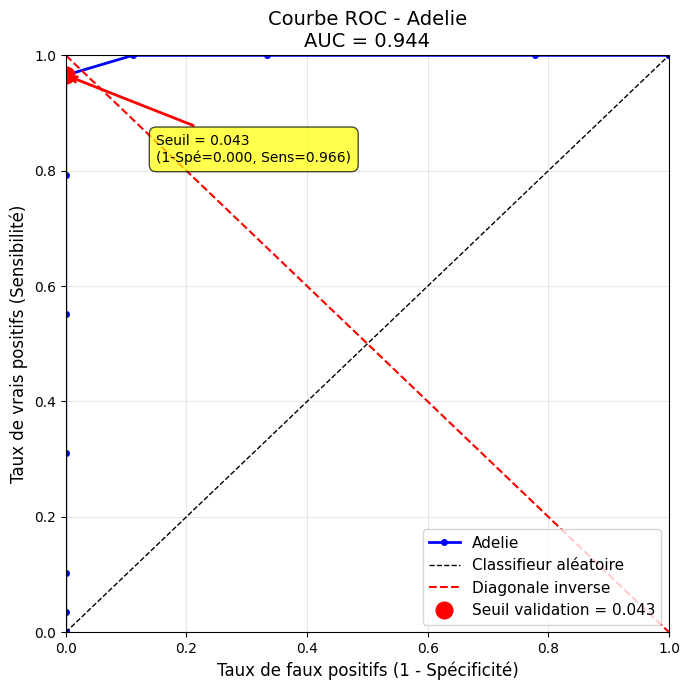


Résultats pour Adelie:
AUC (Aire sous la courbe): 0.944

Seuil optimal (intersection avec diagonale inverse): 0.043
  - Sensibilité: 0.966
  - 1-Spécificité: 0.000
→ Excellent classifieur !


np.float64(0.04296304746705215)

In [4]:
sp0_valid, se0_valid, seuil0_valid= roc_espece(li_poid, Xvalid, Yvalid, espece=0, step=0.1)
seuil0_opti_valid, x0_opti_valid, y0_opti_valid=find_seuil_optimal(sp0_valid, se0_valid, seuil0_valid)
auc0_valid= calculer_auc(sp0_valid, se0_valid)
plot_roc_espece(sp0_valid, se0_valid ,seuil0_opti_valid, x0_opti_valid, y0_opti_valid, auc0_valid, espece=0)

Pour chaque seuil de décision, nous calculons :

- la sensibilité, qui correspond au taux de vrais positifs ;
- la spécificité, qui correspond au taux de vrais négatifs ;
- le taux de faux positifs, égal é `1 - spécificité`.

La courbe ROC représente la sensibilité en fonction du taux de faux positifs pour l'ensemble des seuils testés. Elle permet d'observer le compromis entre la détection correcte des exemples positifs et le nombre de faux positifs.

Dans ce projet, nous définissons le seuil optimal comme le seuil pour lequel la sensibilité et la spécificité sont les plus proches. Graphiquement, il correspond au point de la courbe ROC le plus proche de la diagonale inverse selon ce critère. Ce choix est propre à notre expérimentation : il ne correspond pas nécessairement au meilleur seuil pour tous les objectifs possibles.

Nous appliquons ensuite la même analyse aux trois neurones.


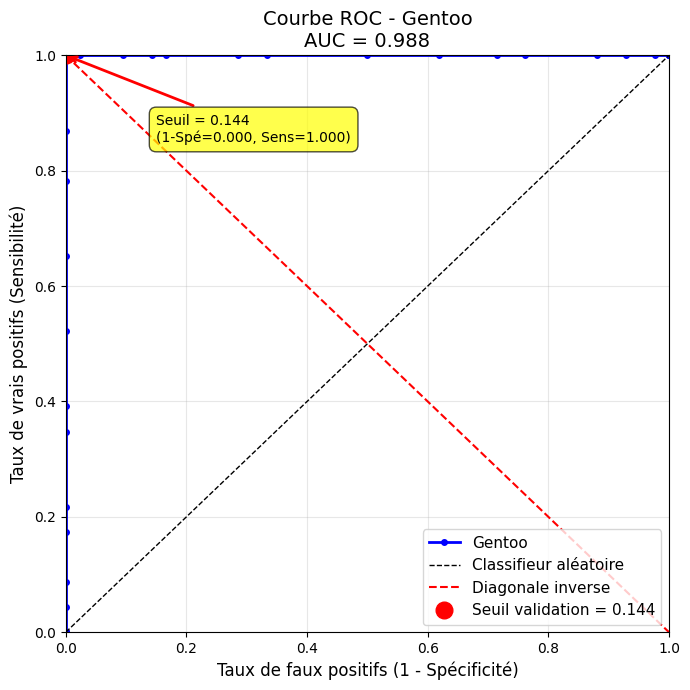


Résultats pour Gentoo:
AUC (Aire sous la courbe): 0.988

Seuil optimal (intersection avec diagonale inverse): 0.144
  - Sensibilité: 1.000
  - 1-Spécificité: 0.000
→ Excellent classifieur !


np.float64(0.1435595571721029)

In [5]:
sp1_valid, se1_valid, seuil1_valid= roc_espece(li_poid, Xvalid, Yvalid, espece=1, step=0.1)
seuil1_opti_valid, x1_opti_valid, y1_opti_valid=find_seuil_optimal(sp1_valid, se1_valid, seuil1_valid)
auc1_valid = calculer_auc(sp1_valid, se1_valid)
plot_roc_espece(sp1_valid, se1_valid,seuil1_opti_valid, x1_opti_valid, y1_opti_valid, auc1_valid, espece=1)

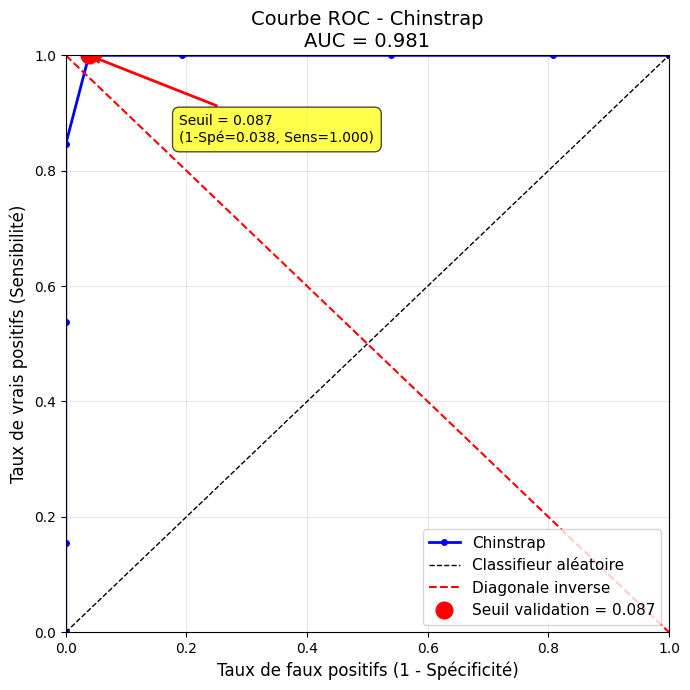


Résultats pour Chinstrap:
AUC (Aire sous la courbe): 0.981

Seuil optimal (intersection avec diagonale inverse): 0.087
  - Sensibilité: 1.000
  - 1-Spécificité: 0.038
→ Excellent classifieur !


np.float64(0.08711603248694977)

In [6]:
sp2_valid, se2_valid, seuil2_valid= roc_espece(li_poid, Xvalid, Yvalid, espece=2, step=0.1)
seuil2_opti_valid, x2_opti_valid, y2_opti_valid=find_seuil_optimal(sp2_valid, se2_valid, seuil2_valid)
auc2_valid = calculer_auc(sp2_valid, se2_valid)
plot_roc_espece(sp2_valid, se2_valid, seuil2_opti_valid, x2_opti_valid, y2_opti_valid, auc2_valid, espece=2)

L'espèce Chinstrap est moins représentée dans le jeu de données que les espèces Adelie et Gentoo.

Après la séparation en ensembles d'apprentissage, de validation et de test, cette classe dispose donc de moins d'observations. Les métriques associées peuvent étre plus sensibles à la séparation alétoire et donc plus instables.

Lorsque l'AUC est proche de 0,5, le neurone distingue peu la classe étudiée des autres classes. Son comportement est alors proche de celui d'un classifieur alétoire.


Les valeurs d'AUC obtenues sont élevées. Cela indique que les scores produits par les neurones séparent correctement les espèces sur l'ensemble évalué.

Cette bonne séparation peut s'expliquer par le caractère discriminant des caractéristiques morphologiques utilisées. Les résultats doivent toutefois étre interprétés avec prudence, car le jeu de données est de taille limitée et les performances dépendent de la séparation alétoire rélisée.

#### 2. Courbe précision-rappel

La courbe précision-rappel représente la précision en fonction du rappel pour différents seuils de décision.

- La précision correspond à la proportion de prédictions positives qui sont réellement positives ;
- le rappel correspond à la proportion d'exemples positifs correctement détectés.

L'Average Precision (AP) résume cette courbe en une valeur unique. Dans ce projet, elle est calculée comme une approximation de l'aire sous la courbe précision-rappel.

L'AP est particulièrement utile lorsque les classes sont déséquilibrées, car elle se concentre sur la qualité des prédictions positives.


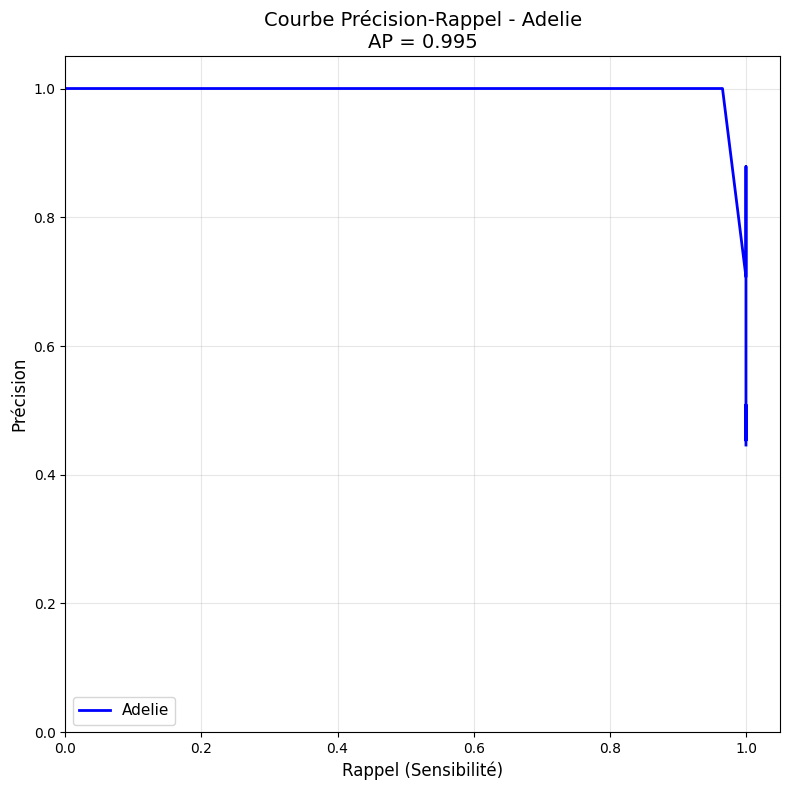


Average Precision (AP) pour Adelie: 0.995


In [7]:
pres0_valid, rap0_valid=pr_especes(li_poid, Xvalid, Yvalid, espece=0, step=0.1)
ap0_valid = calculer_ap(pres0_valid, rap0_valid)
plot_pr_espece(pres0_valid, rap0_valid, ap0_valid, espece=0)


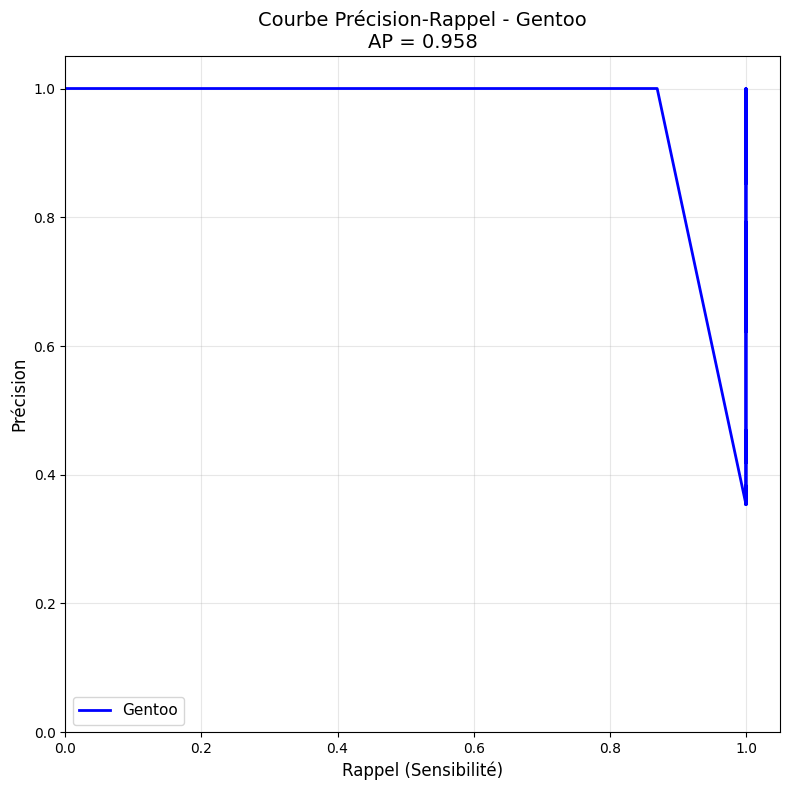


Average Precision (AP) pour Gentoo: 0.958


In [8]:
pres1_valid, rap1_valid=pr_especes(li_poid, Xvalid, Yvalid, espece=1, step=0.1)
ap1_valid = calculer_ap(pres1_valid, rap1_valid)
plot_pr_espece(pres1_valid, rap1_valid, ap1_valid, espece=1)

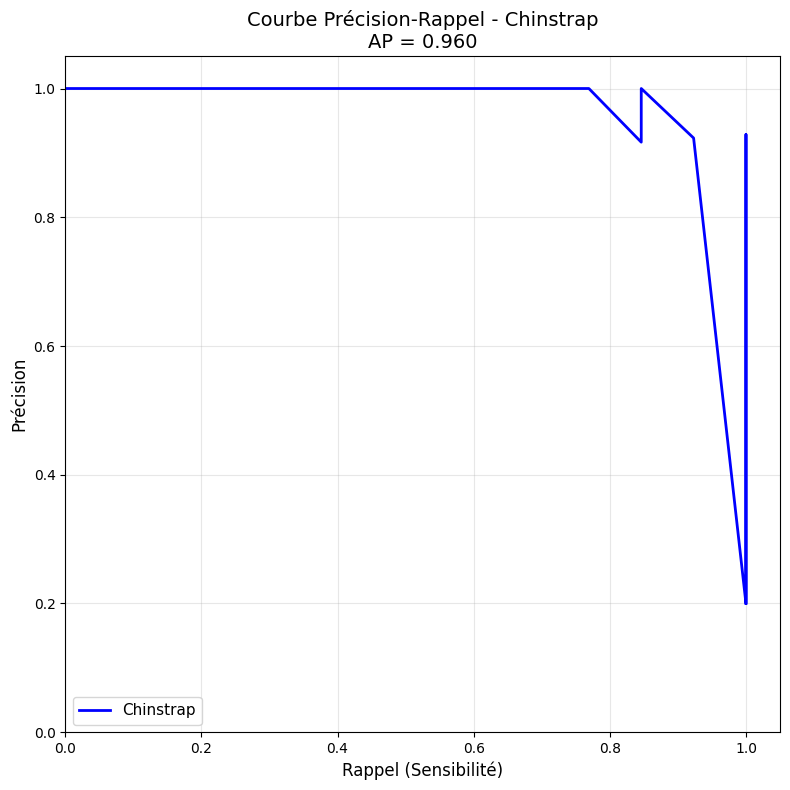


Average Precision (AP) pour Chinstrap: 0.960


In [9]:
pres2_valid, rap2_valid=pr_especes(li_poid, Xvalid, Yvalid, espece=2, step=0.01)
ap2_valid = calculer_ap(pres2_valid, rap2_valid)
plot_pr_espece(pres2_valid, rap2_valid, ap2_valid, espece=2)

### Analyse des métriques globales : MAP et MAUC

Le MAP correspond à la moyenne des AP calculées pour les différentes espèces. Il résume la qualité des courbes précision-rappel de l'ensemble des classes.

Le MAUC correspond à la moyenne des AUC calculées pour les différentes espèces. Il résume la capacité moyenne du modèle é séparer chaque espèce des autres.

Ces métriques fournissent une vision globale, mais elles peuvent masquer des différences importantes entre les classes. Il est donc nécessaire de présenter également les valeurs obtenues pour chaque espèce.


### 3) Ensemble de test

Les seuils optimaux ont été déterminés uniquement à partir de l'ensemble de validation.

Ils sont maintenant appliqués à l'ensemble de test, qui n'a pas été utilisé pour régler les seuils. Cette procédure permet d'obtenir une estimation plus honnéte des performances finales du modèle.


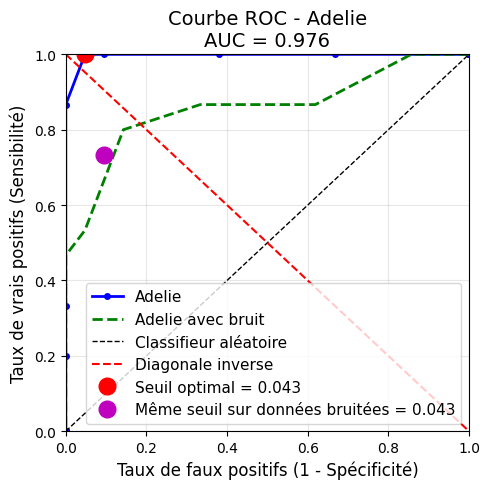


Résultats pour Adelie:
AUC (Aire sous la courbe): 0.976

Seuil optimal (intersection avec diagonale inverse): 0.043
  - Sensibilité: 1.000
  - 1-Spécificité: 0.048
→ Excellent classifieur !


np.float64(0.04296304746705215)

In [10]:
sp0_test, se0_test, seuil0_test= roc_espece(li_poid, Xtest, Ytest, espece=0, step=0.1)
seuil0_opti_test = seuil0_opti_valid
x0_opti_test, y0_opt_test = point_roc_pour_seuil(li_poid, Xtest, Ytest, 0, seuil0_opti_test)
auc0_test= calculer_auc(sp0_test, se0_test)

sp0_test_bruit, se0_test_bruit, seuil0_test_bruit= roc_espece(li_poid, Xtest_bruit, Ytest, espece=0, step=0.1)
seuil0_opti_test_bruit = seuil0_opti_valid
x0_opti_test_bruit, y0_opt_test_bruit = point_roc_pour_seuil(li_poid, Xtest_bruit, Ytest, 0, seuil0_opti_test_bruit)
auc0_test_bruit= calculer_auc(sp0_test_bruit, se0_test_bruit)



plot_roc_espece_bruit(sp0_test, sp0_test_bruit, se0_test, se0_test_bruit, seuil0_opti_test, seuil0_opti_test_bruit, x0_opti_test,x0_opti_test_bruit, y0_opt_test, y0_opt_test_bruit, auc0_test, auc0_test_bruit, espece=0)

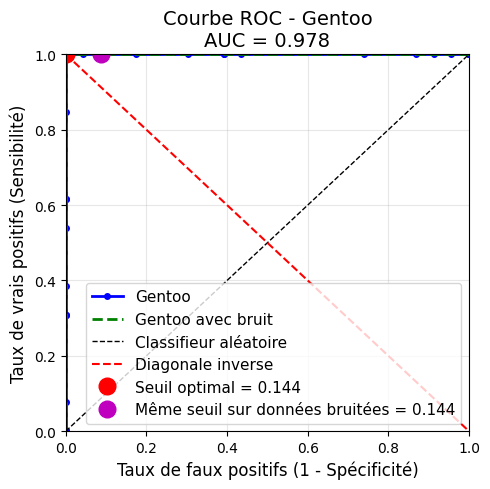


Résultats pour Gentoo:
AUC (Aire sous la courbe): 0.978

Seuil optimal (intersection avec diagonale inverse): 0.144
  - Sensibilité: 1.000
  - 1-Spécificité: 0.000
→ Excellent classifieur !


np.float64(0.1435595571721029)

In [11]:
sp1_test, se1_test, seuil1_test= roc_espece(li_poid, Xtest, Ytest, espece=1, step=0.1)
seuil1_opti_test = seuil1_opti_valid
x1_opti_test, y1_opt_test = point_roc_pour_seuil(li_poid, Xtest, Ytest, 1, seuil1_opti_test)
auc1_test= calculer_auc(sp1_test, se1_test)

sp1_test_bruit, se1_test_bruit, seuil1_test_bruit= roc_espece(li_poid, Xtest_bruit, Ytest, espece=1, step=0.1)
seuil1_opti_test_bruit = seuil1_opti_valid
x1_opti_test_bruit, y1_opt_test_bruit = point_roc_pour_seuil(li_poid, Xtest_bruit, Ytest, 1, seuil1_opti_test_bruit)
auc1_test_bruit= calculer_auc(sp1_test_bruit, se1_test_bruit)



plot_roc_espece_bruit(sp1_test, sp1_test_bruit, se1_test, se1_test_bruit, seuil1_opti_test, seuil1_opti_test_bruit, x1_opti_test,x1_opti_test_bruit, y1_opt_test, y1_opt_test_bruit, auc1_test, auc1_test_bruit, espece=1)

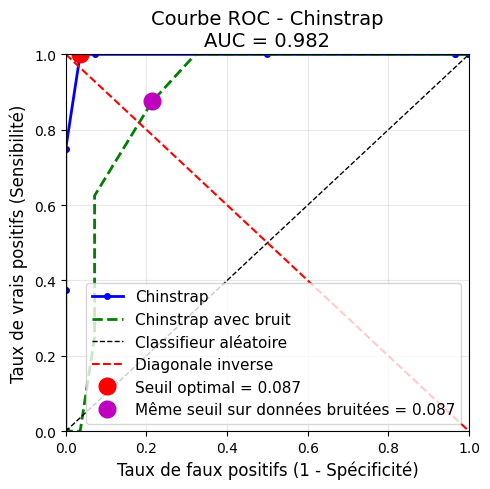


Résultats pour Chinstrap:
AUC (Aire sous la courbe): 0.982

Seuil optimal (intersection avec diagonale inverse): 0.087
  - Sensibilité: 1.000
  - 1-Spécificité: 0.036
→ Excellent classifieur !


np.float64(0.08711603248694977)

In [12]:
sp2_test, se2_test, seuil2_test= roc_espece(li_poid, Xtest, Ytest, espece=2, step=0.1)
seuil2_opti_test = seuil2_opti_valid
x2_opti_test, y2_opt_test = point_roc_pour_seuil(li_poid, Xtest, Ytest, 2, seuil2_opti_test)
auc2_test= calculer_auc(sp2_test, se2_test)

sp2_test_bruit, se2_test_bruit, seuil2_test_bruit= roc_espece(li_poid, Xtest_bruit, Ytest, espece=2, step=0.1)
seuil2_opti_test_bruit = seuil2_opti_valid
x2_opti_test_bruit, y2_opt_test_bruit = point_roc_pour_seuil(li_poid, Xtest_bruit, Ytest, 2, seuil2_opti_test_bruit)
auc2_test_bruit= calculer_auc(sp2_test_bruit, se2_test_bruit)



plot_roc_espece_bruit(sp2_test, sp2_test_bruit, se2_test, se2_test_bruit, seuil2_opti_test, seuil2_opti_test_bruit, x2_opti_test,x2_opti_test_bruit, y2_opt_test, y2_opt_test_bruit, auc2_test, auc2_test_bruit, espece=2)

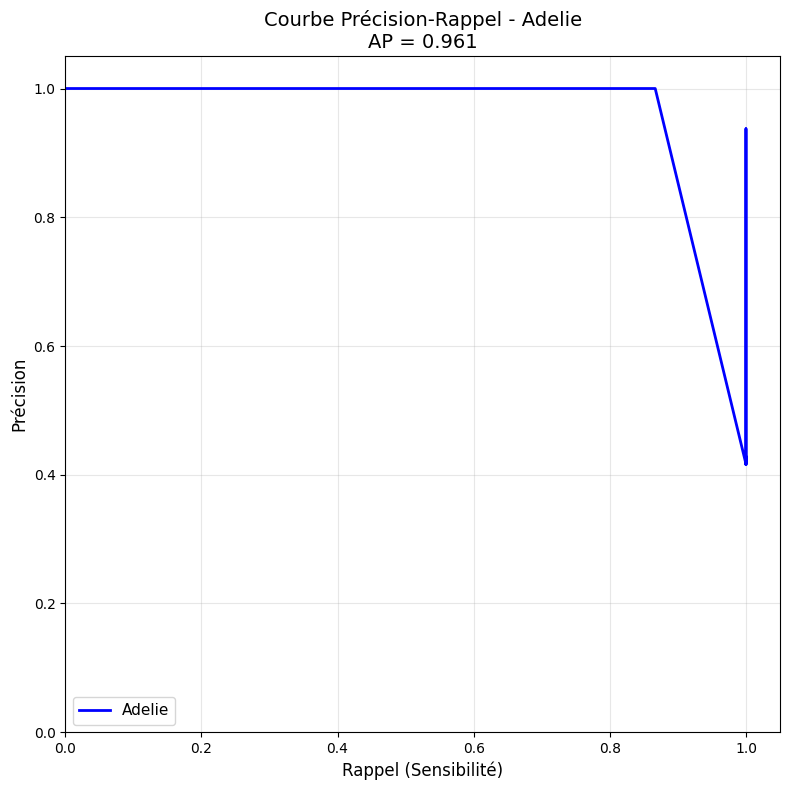


Average Precision (AP) pour Adelie: 0.961


In [13]:
pres0, rap0=pr_especes(li_poid, Xtest, Ytest, espece=0, step=0.1)
ap0 = calculer_ap(pres0, rap0)
plot_pr_espece(pres0, rap0, ap0, espece=0)


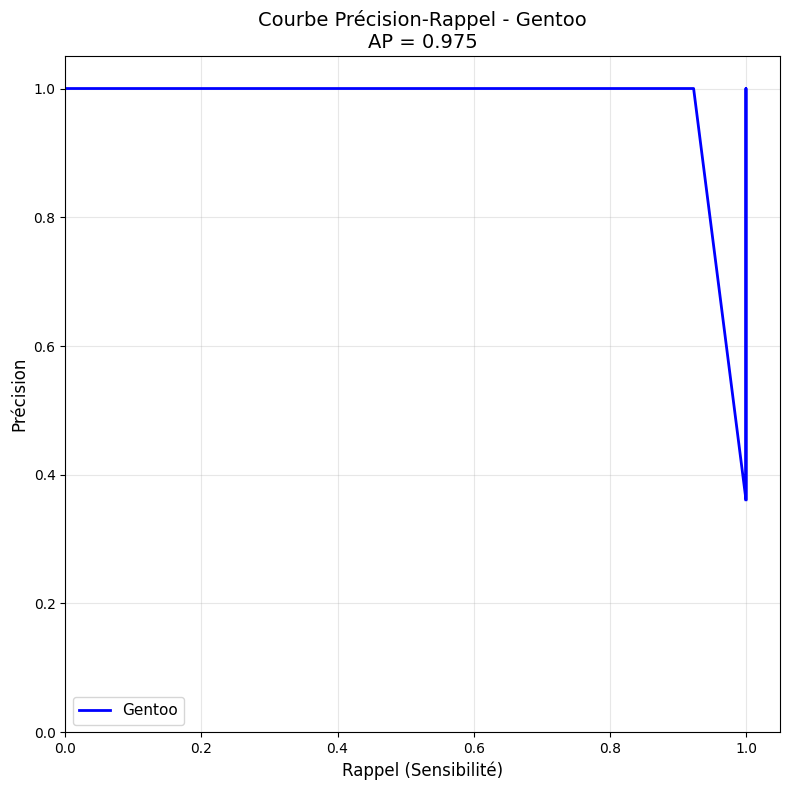


Average Precision (AP) pour Gentoo: 0.975


In [14]:
pres1, rap1=pr_especes(li_poid, Xtest, Ytest, espece=1, step=0.01)
ap1= calculer_ap(pres1, rap1)
plot_pr_espece(pres1, rap1, ap1, espece=1)

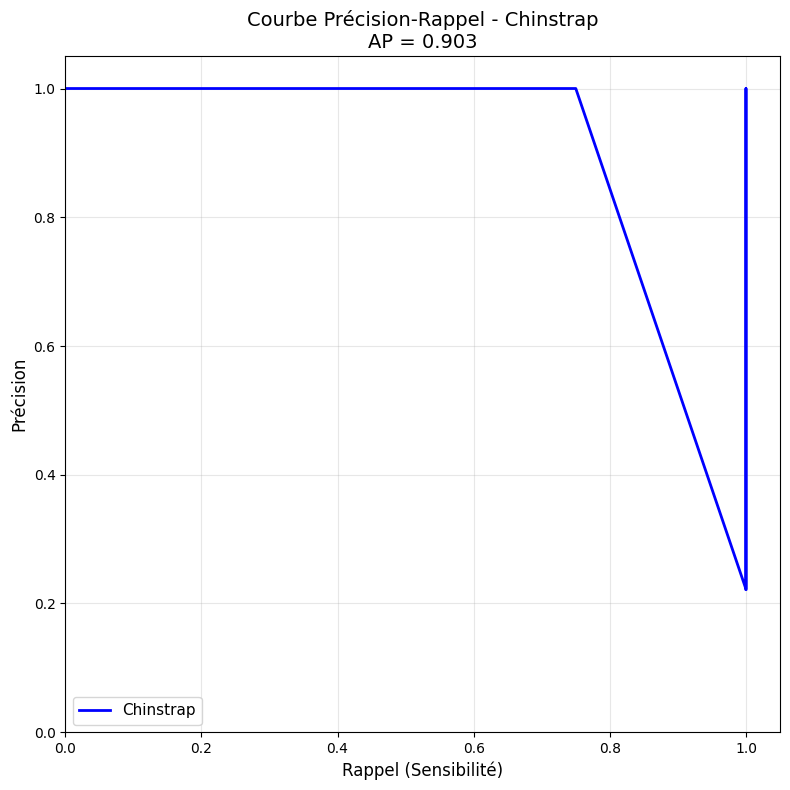


Average Precision (AP) pour Chinstrap: 0.903


In [15]:
pres2, rap2=pr_especes(li_poid, Xtest, Ytest, espece=2, step=0.01)
ap2 = calculer_ap(pres2, rap2)
plot_pr_espece(pres2, rap2, ap2, espece=2)


COMPARAISON DES PERFORMANCES

Avec seuil unique 0 (le seuil utilisé pour l'apprentissage):

Sans bruit:
taux de bonne classification : 0.9444444444444444


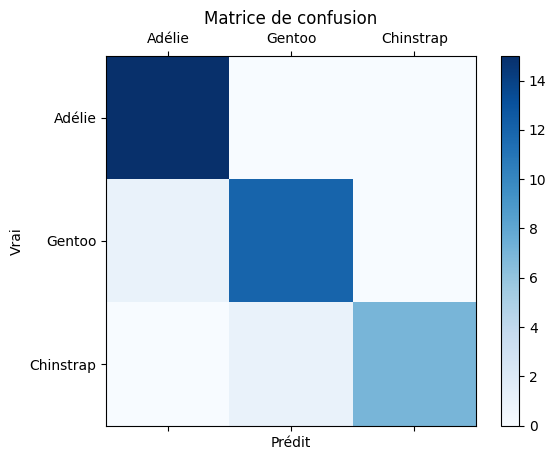


Avec bruit:
taux de bonne classification : 0.7777777777777778


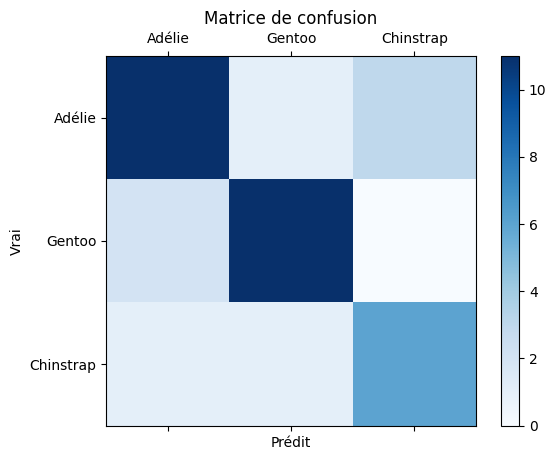


Avec seuils optimaux déterminés sur la validation: [np.float64(0.04296304746705215), np.float64(0.1435595571721029), np.float64(0.08711603248694977)]

Sans bruit:
taux de bonne classification : 0.9722222222222222


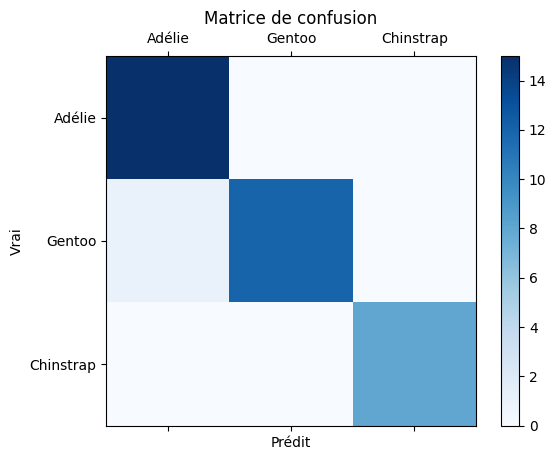


Avec bruit:
taux de bonne classification : 0.8333333333333334


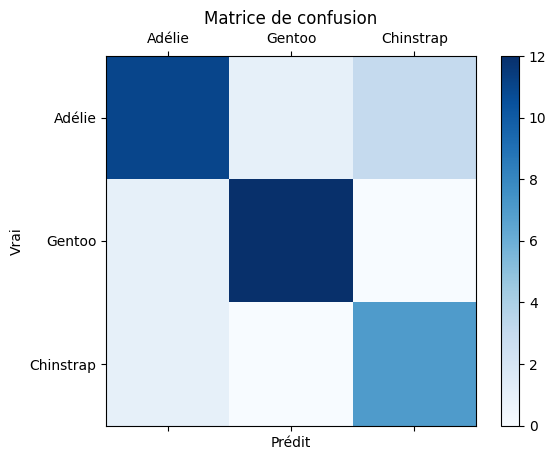

In [16]:
seuils_optimaux_test= [seuil0_opti_valid, seuil1_opti_valid, seuil2_opti_valid]
seuils_optimaux_test_bruit= [seuil0_opti_valid, seuil1_opti_valid, seuil2_opti_valid]
# Maintenant qu'on a les seuils optimaux, on teste sur le set de test avec ces seuils
matrice_conf_test_opti= test_avec_seuils_optimaux(Xtest, Ytest, li_poid, seuils_optimaux_test)
matrice_conf_test = test(Xtest, Ytest, li_poid, seuil_appr)

matrice_conf_test_bruit= test_avec_seuils_optimaux(Xtest_bruit, Ytest, li_poid, seuils_optimaux_test_bruit)
matrice_conf_bruit = test(Xtest_bruit, Ytest, li_poid, seuil_appr)
print("\n" + "="*60)
print("COMPARAISON DES PERFORMANCES")
print("="*60)
print(f"\nAvec seuil unique {seuil_appr} (le seuil utilisé pour l'apprentissage):")
print("\nSans bruit:")
taux_bonne_classification(matrice_conf_test)
plot_confusion_matrix(matrice_conf_test)
print("\nAvec bruit:")
taux_bonne_classification(matrice_conf_bruit)
plot_confusion_matrix(matrice_conf_bruit)

print("\nAvec seuils optimaux déterminés sur la validation:", seuils_optimaux_test)
print("\nSans bruit:")
taux_bonne_classification(matrice_conf_test_opti)
plot_confusion_matrix(matrice_conf_test_opti)
print("\nAvec bruit:")
taux_bonne_classification(matrice_conf_test_bruit)
plot_confusion_matrix(matrice_conf_test_bruit)



L'utilisation des seuils optimaux permet de réduire les erreurs sur l'ensemble évalué. Cette observation doit toutefois étre interprétée avec prudence, car les seuils ont été choisis à partir de l'ensemble de validation et les performances finales doivent étre mesurées sur le test.

Nous étudions ensuite l'effet de l'ajout d'un bruit artificiel aux caractéristiques.


In [17]:
# Calcul et affichage des métriques pour les test
map_score = (ap0 + ap1 + ap2) / 3
mauc_score = (auc0_test + auc1_test + auc2_test) / 3

print("="*80)
print("RÉSULTATS DE NOTRE MODÈLE")
print("="*80)
print(f"\nMétriques par espèce :")
print(f"  • Adelie    : AP = {ap0:.4f}  |  AUC = {auc0_test:.4f}")
print(f"  • Gentoo    : AP = {ap1:.4f}  |  AUC = {auc1_test:.4f}")
print(f"  • Chinstrap : AP = {ap2:.4f}  |  AUC = {auc2_test:.4f}")
print(f"\nMétriques globales :")
print(f"  • MAP (Mean Average Precision) : {map_score:.4f}")
print(f"  • MAUC (Mean Area Under Curve) : {mauc_score:.4f}")



RÉSULTATS DE NOTRE MODÈLE

Métriques par espèce :
  • Adelie    : AP = 0.9611  |  AUC = 0.9762
  • Gentoo    : AP = 0.9754  |  AUC = 0.9783
  • Chinstrap : AP = 0.9028  |  AUC = 0.9821

Métriques globales :
  • MAP (Mean Average Precision) : 0.9464
  • MAUC (Mean Area Under Curve) : 0.9789


### 4) Recherche du nombre optimal de folds

La validation croisée k-fold divise les données en plusieurs sous-ensembles. À chaque itération, un sous-ensemble sert à la validation et les autres à l'apprentissage.

Dans notre implémentation, nous comparons le MAUC obtenu sur l'apprentissage et celui obtenu sur la validation. Le nombre de folds retenu est celui qui minimise en moyenne lécart absolu entre ces deux valeurs.

Ce critère cherche à limiter lécart de généralisation. Il ne garantit pas que le k sélectionné maximise directement la performance absolue du modèle.


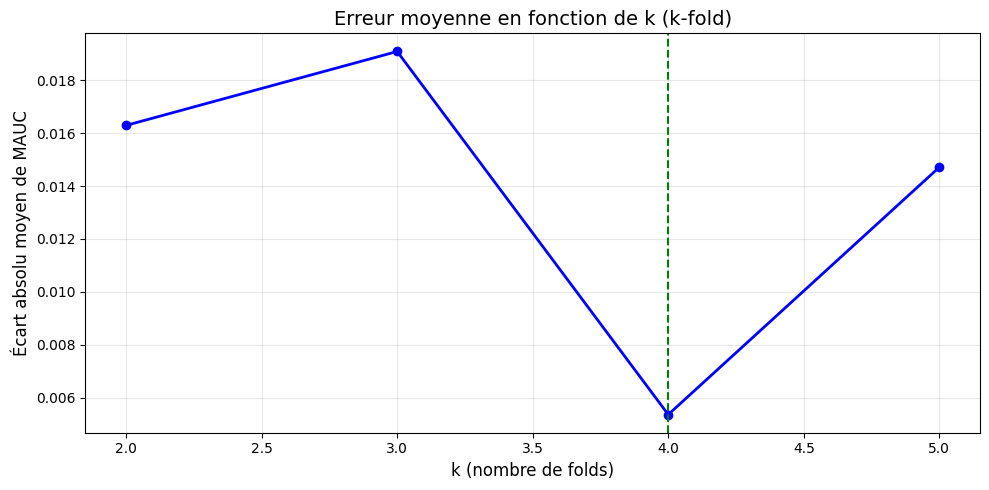

In [18]:
# Recherche du k optimal et comparaison de l'erreur de généralisation
k_etoile, li_erreur_k, li_k = find_k_etoile(
    nb_folds_max=5, lr=lr, etapes=100, donnees=(entrees, sorties)
)
plot_find_k_etoile(k_etoile, li_erreur_k, li_k)


### 5) Recherche du nombre optimal d'époques

Le nombre optimal d'époques est sélectionné comme l'époque pour laquelle le MAUC de validation est maximal.

Ce choix peut limiter le sur-entraînement, car il privilégie le moment où le modèle généralise le mieux sur les données de validation. Il ne s'agit toutefois pas d'un arrét anticipé complet : l'apprentissage est d'abord effectué jusqu'au nombre d'époques demandé.



Étape optimale (t_etoile) basée sur la validation : 39


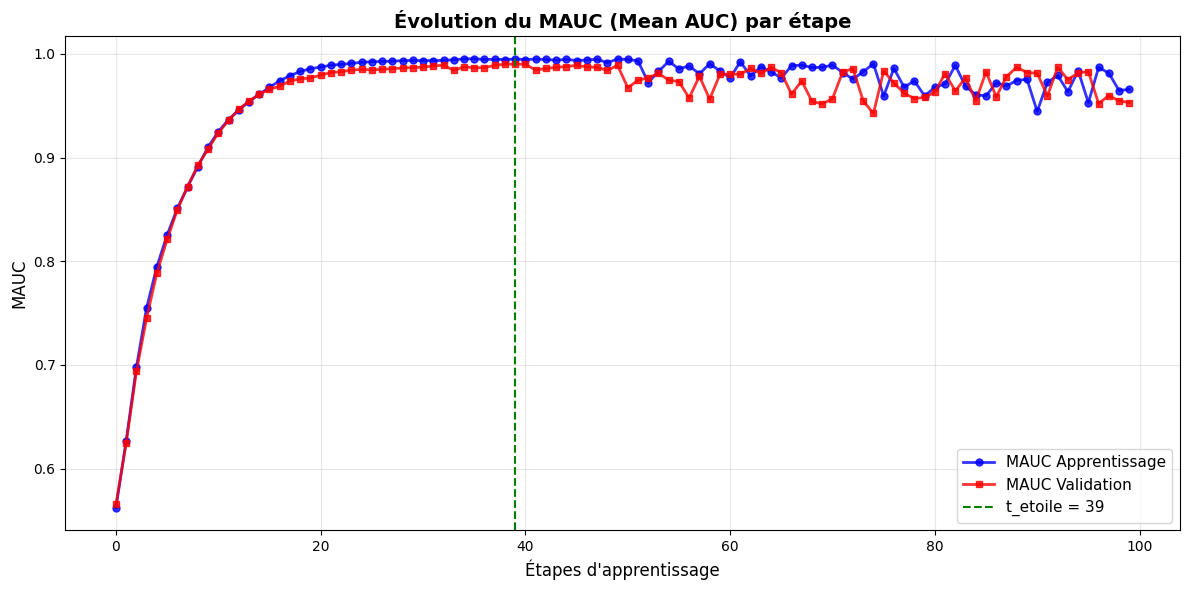


Statistiques du MAUC

Apprentissage:
  MAUC initial: 0.5622
  MAUC final: 0.9659
  MAUC moyen: 0.9608
  MAUC max: 0.9953 (étape 35)
  MAUC min: 0.5622 (étape 0)

Validation:
  MAUC initial: 0.5654
  MAUC final: 0.9530
  MAUC moyen: 0.9546
  MAUC max: 0.9901 (étape 39)
  MAUC min: 0.5654 (étape 0)


In [19]:
# Suivi du MAUC pour le k optimal
mauc_app, mauc_valid = t_etoile(
    k_etoile, lr, 100, seuil=seuil_appr, donnees=(entrees, sorties)
)
plot_t_etoile(mauc_app, mauc_valid)


Le nombre optimal d'époques a été estimé à partir du MAUC de validation. Cette valeur peut ensuite étre utilisée pour relancer l'expérience finale avec un nombre d'époques mieux adapté.


## Conclusion

Ce projet nous a permis d'implémenter et détudier un perceptron monocouche pour classifier trois espèces de manchots à partir de leurs caractéristiques morphologiques.

L'analyse des seuils de décision, des courbes ROC et précision-rappel ainsi que des métriques AUC, AP, MAP et MAUC permet d'évaluer le comportement du modèle sous différents angles.

Les résultats obtenus montrent que le perceptron sépare correctement les espèces sur ce jeu de données. Les performances sont toutefois é interpréter avec prudence, car le dataset est de taille limitée et les classes ne sont pas représentées de manière parfaitement équilibrée.

L'expérience avec ajout de bruit permet détudier la robustesse du modèle et montre l'effet de perturbations artificielles sur les performances. Enfin, la recherche du nombre de folds et du nombre d'époques fournit une méthode pour sélectionner les paramètres à partir des performances de validation.

Ce travail présente néanmoins certaines limites : le modèle est simple, le bruit utilisé est artificiel et les métriques sont implémentées à des fins pédagogiques. Une étude complémentaire pourrait comparer ces résultats avec des modèles de référence de scikit-learn et utiliser une validation croisée plus compléte.


## Ressources

Tout le code est disponible [ici](./src/)